# Data Cleaning & Quality Checker

## 1. Project Overview

The Data Cleaning & Quality Checker is a Python-based data
analysis project designed to identify, analyze, and address
common data quality issues in structured datasets.

The project uses Python, pandas, NumPy, and openpyxl to
inspect raw data, detect missing values and duplicate records,
standardize inconsistent data, identify potential outliers,
and generate quality reports.

The final output includes a cleaned dataset and an Excel
report summarizing data quality issues and cleaning results.

## 2. Problem Statement

Raw datasets often contain missing values, duplicate records,
inconsistent text formatting, incorrect data types, and
potentially unusual numerical values.

These problems can reduce data reliability and affect the
accuracy of reports and analytical results.

This project aims to develop a systematic workflow for
identifying data quality issues, applying appropriate cleaning
operations, and evaluating the dataset before and after cleaning.

## 3. Project Objectives

The main objectives of this project are:

1. Load structured data from CSV and Excel files.
2. Understand the structure and characteristics of the dataset.
3. Detect missing values and calculate missing-value percentages.
4. Identify duplicate records.
5. Standardize inconsistent text formatting.
6. Validate data types and numerical values.
7. Identify potential outliers using statistical methods.
8. Apply suitable data cleaning techniques.
9. Compare data quality before and after cleaning.
10. Export cleaned data and generate an Excel quality report.

## 4. Technology Stack

| Technology | Purpose |
|---|---|
| Python | Main programming language |
| Jupyter Notebook | Interactive development and documentation |
| pandas | Data loading, analysis, and cleaning |
| NumPy | Numerical calculations and statistical operations |
| openpyxl | Excel report generation and formatting |
| Matplotlib | Data visualization and quality comparisons |

In [1]:
%pip install pandas numpy openpyxl matplotlib

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [2]:
# impoart necessary libraries

import pandas as pd
import numpy as np
import openpyxl
import matplotlib.pyplot as plt

In [3]:
# check the version of the libraries

print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("openpyxl version:", openpyxl.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

pandas version: 3.1.0
NumPy version: 2.5.4
openpyxl version: 3.1.5
Matplotlib version: 3.11.2


# 5. Dataset Creation and Data Loading

## 5.1 Dataset Description

This project uses a sample customer dataset to demonstrate
data cleaning and quality assessment techniques.

The dataset contains customer identifiers, names, email
addresses, ages, cities, annual incomes, and registration dates.

Artificial data-quality issues will be introduced to test
the effectiveness of the data cleaning workflow.

## 5.2 Dataset Objectives

- Understand the structure of customer data.
- Identify missing values and duplicate records.
- Detect inconsistent text and invalid values.
- Evaluate numerical columns.
- Prepare the dataset for systematic data cleaning.

In [4]:
import pandas as pd

data = {
    "customer_id": [1001, 1002, 1003, 1003, 1004, 1005],
    "name": [
        "Rahul Sharma",
        "Priya Verma",
        "Amit Kumar",
        "Amit Kumar",
        "Neha Singh",
        "Ravi Kumar"
    ]
}

df = pd.DataFrame(data)

df

,customer_id,name
0,1001,Rahul Sharma
1,1002,Priya Verma
2,1003,Amit Kumar
3,1003,Amit Kumar
4,1004,Neha Singh
5,1005,Ravi Kumar


In [6]:
df = pd.DataFrame(data)
df

,customer_id,name
0,1001,Rahul Sharma
1,1002,Priya Verma
2,1003,Amit Kumar
3,1003,Amit Kumar
4,1004,Neha Singh
5,1005,Ravi Kumar


### Creating CSV File

In [19]:
import pandas as pd
from pathlib import Path

# Project ke data folder ka path
data_folder = Path("../data")

# Folder exist nahi karta, toh create karo
data_folder.mkdir(parents=True, exist_ok=True)

# Sample customer data
data = {
    "customer_id": [1001, 1002, 1003, 1003, 1004, 1005],
    "name": [
        "Rahul Sharma", "Priya Verma", "Amit Kumar",
        "Amit Kumar", "Neha Singh", "Ravi Kumar"
    ],
    "email": [
        "rahul@example.com", "priya@example.com",
        "amit@example.com", "amit@example.com",
        "neha@example.com", None
    ],
    "age": [24, None, 29, 29, 150, 27],
    "city": ["Delhi", "Mumbai", "Delhi", "Delhi", "mumbai", "Delhi"],
    "annual_income": [420000, 580000, 610000, 610000, 450000, 390000],
    "signup_date": [
        "2024-01-12", "2024-02-18", "2024-03-07",
        "2024-03-07", "2024-04-29", "2024-05-10"
    ]
}

# DataFrame create karo
df = pd.DataFrame(data)

# CSV file mein save karo
df.to_csv(data_folder / "customer.csv", index=False)

print("CSV file successfully created!")
print("Dataset shape:", df.shape)

df

CSV file successfully created!
Dataset shape: (6, 7)


,customer_id,name,email,age,city,annual_income,signup_date
0,1001,Rahul Sharma,rahul@example.com,24.0,Delhi,420000,2024-01-12
1,1002,Priya Verma,priya@example.com,NaN,Mumbai,580000,2024-02-18
2,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07
3,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07
4,1004,Neha Singh,neha@example.com,150.0,mumbai,450000,2024-04-29
5,1005,Ravi Kumar,NaN,27.0,Delhi,390000,2024-05-10


In [20]:
df = pd.read_csv(data_folder / "customer.csv")

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

df.head()

Dataset shape: (6, 7)
Column names: ['customer_id', 'name', 'email', 'age', 'city', 'annual_income', 'signup_date']


,customer_id,name,email,age,city,annual_income,signup_date
0,1001,Rahul Sharma,rahul@example.com,24.0,Delhi,420000,2024-01-12
1,1002,Priya Verma,priya@example.com,NaN,Mumbai,580000,2024-02-18
2,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07
3,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07
4,1004,Neha Singh,neha@example.com,150.0,mumbai,450000,2024-04-29


## 6. Missing Value Analysis

### Objective
The objective of this stage is to identify and analyze
missing values in the customer dataset.

Missing values can affect data analysis and the accuracy
of results. Therefore, it is important to identify them
before performing further data cleaning operations.

### Tasks
- Identify missing values in each column.
- Calculate the total number of missing values.
- Calculate the percentage of missing values.
- Summarize the missing-value analysis.

In [22]:
# Missing values identify

df.isnull()

,customer_id,name,email,age,city,annual_income,signup_date
0,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
5,False,False,True,False,False,False,False


In [23]:
# missing values count 

df.isnull().sum()

customer_id      0
name             0
email            1
age              1
city             0
annual_income    0
signup_date      0
dtype: int64

In [24]:
#total missing values calculate


total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 2


In [26]:
# Missing values percentage calculate

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

customer_id       0.000000
name              0.000000
email            16.666667
age              16.666667
city              0.000000
annual_income     0.000000
signup_date       0.000000
dtype: float64

In [27]:
# summary table

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary["Missing Percentage"] = (
    missing_summary["Missing Percentage"].round(2)
)

missing_summary

,Missing Values,Missing Percentage
customer_id,0,0.00
name,0,0.00
email,1,16.67
age,1,16.67
city,0,0.00
annual_income,0,0.00
signup_date,0,0.00


### 6.1 Missing Value Analysis Findings

The dataset contains 6 records and 7 columns.

The missing value analysis identified 2 missing values
in the dataset.

- The email column contains 1 missing value.
- The age column contains 1 missing value.
- Each missing value represents approximately 16.67%
  of the dataset's records.
- The remaining columns do not contain missing values.

These missing values will be evaluated during the
data cleaning stage before deciding how to handle them.

## 7. Duplicate Record Detection

### Objective
The objective of this stage is to identify duplicate
records in the customer dataset.

Duplicate records can affect data accuracy and may lead
to incorrect analysis or reporting.

### Tasks
- Identify duplicate rows.
- Count duplicate records.
- Display duplicate records.
- Remove duplicate records when appropriate.
- Verify the cleaned dataset.

In [28]:
# total records checks

print("Total records:", len(df))

Total records: 6


In [29]:
#Duplicate records identify

df.duplicated()

0    False
1    False
2    False
3     True
4    False
5    False
dtype: bool

In [30]:
# Duplicate records total count

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 1


In [31]:
# Duplicate rows display

duplicates = df[df.duplicated()]

duplicates

,customer_id,name,email,age,city,annual_income,signup_date
3,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07


In [32]:
# Duplicate records remove

df_no_duplicates = df.drop_duplicates()

print("Original records:", len(df))
print("Records after duplicate removal:", len(df_no_duplicates))
print("Duplicates remaining:", df_no_duplicates.duplicated().sum())

Original records: 6
Records after duplicate removal: 5
Duplicates remaining: 0


In [33]:
# Unique customer IDs check

print("Unique customer IDs:", df["customer_id"].nunique())
print("Total records:", len(df))

Unique customer IDs: 5
Total records: 6


In [ ]:
# repeated customer ID  detail

df[df["customer_id"].duplicated(keep=False)].sort_values("customer_id")

,customer_id,name,email,age,city,annual_income,signup_date
2,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07
3,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07


### 7.1 Duplicate Detection Findings

The duplicate record analysis identified one fully
duplicated row in the sample dataset.

- Original number of records: 6
- Number of duplicate rows identified: 1
- Number of records after duplicate removal: 5
- Number of remaining duplicate rows: 0

The duplicated record belongs to customer ID 1003.

A cleaned copy of the dataset was created using the
Pandas `drop_duplicates()` method. The original
dataset was preserved for comparison and auditing.

In [36]:
# cleaned DataFrame set
df = df_no_duplicates.copy()

df.shape


(5, 7)

In [37]:
df_no_duplicates.shape

(5, 7)

In [38]:
df_no_duplicates.duplicated().sum()

np.int64(0)

In [39]:
df_no_duplicates

,customer_id,name,email,age,city,annual_income,signup_date
0,1001,Rahul Sharma,rahul@example.com,24.0,Delhi,420000,2024-01-12
1,1002,Priya Verma,priya@example.com,NaN,Mumbai,580000,2024-02-18
2,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07
4,1004,Neha Singh,neha@example.com,150.0,mumbai,450000,2024-04-29
5,1005,Ravi Kumar,NaN,27.0,Delhi,390000,2024-05-10


## 8. Data Type Validation and Standardization

### Objective
The objective of this stage is to validate the data types
of each column and standardize inconsistent text values.

### Tasks
- Inspect the data types of all columns.
- Convert date columns into datetime format.
- Standardize text values.
- Validate numerical columns.
- Document the changes made during standardization.

In [41]:
# Existing data types check

df.dtypes

customer_id        int64
name                 str
email                str
age              float64
city                 str
annual_income      int64
signup_date          str
dtype: object

In [42]:
# convert Date column to datetime format mein

df["signup_date"] = pd.to_datetime(
    df["signup_date"],
    errors="coerce"
)

df[["customer_id", "signup_date"]]

,customer_id,signup_date
0,1001,2024-01-12
1,1002,2024-02-18
2,1003,2024-03-07
4,1004,2024-04-29
5,1005,2024-05-10


In [43]:
print(df["signup_date"].dtype)

datetime64[us]


In [44]:
# City names standardize

df["city"].value_counts()

city
Delhi     3
Mumbai    1
mumbai    1
Name: count, dtype: int64

In [45]:
df["city"] = df["city"].str.strip().str.title()

df["city"].value_counts()

city
Delhi     3
Mumbai    2
Name: count, dtype: int64

In [46]:
# Column names standardize

df.columns.tolist()

['customer_id', 'name', 'email', 'age', 'city', 'annual_income', 'signup_date']

In [47]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.columns.tolist()

['customer_id', 'name', 'email', 'age', 'city', 'annual_income', 'signup_date']

In [48]:
df.dtypes

customer_id               int64
name                        str
email                       str
age                     float64
city                        str
annual_income             int64
signup_date      datetime64[us]
dtype: object

### 8.1 Data Type Validation and Standardization Findings

The dataset's data types were inspected using Pandas.

The following standardization operations were performed:

- The signup_date column was converted into datetime format.
- Leading and trailing spaces were removed from city values.
- City names were standardized to title case.
- Column names were normalized to lowercase with underscores.

These changes improve consistency and prepare the dataset
for further validation and quality checks.

The age column will be examined separately because it
contains a potentially invalid value.

In [51]:
df["signup_date"].dtype


dtype('<M8[us]')

In [52]:
df["city"].unique()


<StringArray>
['Delhi', 'Mumbai']
Length: 2, dtype: str

In [53]:
df.dtypes

customer_id               int64
name                        str
email                       str
age                     float64
city                        str
annual_income             int64
signup_date      datetime64[us]
dtype: object

## 9. Data Validation and Outlier Detection

### Objective
The objective of this stage is to validate numerical
data and identify unusual or potentially invalid values.

### Tasks
- Define validation rules for customer age.
- Identify missing and invalid age values.
- Inspect numerical columns using descriptive statistics.
- Detect potential outliers using the Interquartile Range (IQR) method.
- Document data quality issues.

In [55]:
# Numerical data ka summary

df.describe()

,customer_id,age,annual_income,signup_date
count,5.000000,4.000000,5.000000,5
mean,1003.000000,57.500000,490000.000000,2024-03-15 19:12:00
min,1001.000000,24.000000,390000.000000,2024-01-12 00:00:00
25%,1002.000000,26.250000,420000.000000,2024-02-18 00:00:00
50%,1003.000000,28.000000,450000.000000,2024-03-07 00:00:00
75%,1004.000000,59.250000,580000.000000,2024-04-29 00:00:00
max,1005.000000,150.000000,610000.000000,2024-05-10 00:00:00
std,1.581139,61.700891,98742.088291,NaN


In [ ]:
# age validation rule

valid_age = df["age"].between(0, 120)

print("Valid age records:", valid_age.sum())
print("Invalid or missing age records:", (~valid_age).sum())

Valid age records: 3
Invalid or missing age records: 2


In [57]:
# Invalid age records identify

invalid_age_records = df[
    df["age"].notna() &
    ~df["age"].between(0, 120)
]

invalid_age_records

,customer_id,name,email,age,city,annual_income,signup_date
4,1004,Neha Singh,neha@example.com,150.0,Mumbai,450000,2024-04-29


In [58]:
# Missing aur invalid ages count 

missing_age_count = df["age"].isna().sum()

invalid_age_count = (
    df["age"].notna() &
    ~df["age"].between(0, 120)
).sum()

print("Missing age values:", missing_age_count)
print("Invalid age values:", invalid_age_count)

Missing age values: 1
Invalid age values: 1


In [59]:
# IQR method - potential outliers identify

age_data = df["age"].dropna()

Q1 = age_data.quantile(0.25)
Q3 = age_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 26.25
Q3: 59.25
IQR: 33.0
Lower bound: -23.25
Upper bound: 108.75


In [60]:
# Potential age outliers display

age_outliers = df[
    df["age"].notna() &
    (
        (df["age"] < lower_bound) |
        (df["age"] > upper_bound)
    )
]

age_outliers

,customer_id,name,email,age,city,annual_income,signup_date
4,1004,Neha Singh,neha@example.com,150.0,Mumbai,450000,2024-04-29


### 9.1 Data Validation and Outlier Detection Findings

The age column was examined using a predefined validation
range of 0 to 120 years.

The analysis identified:
- One missing age value.
- One age value outside the defined validation range.
- Potential age outliers using the Interquartile Range (IQR) method.

The record with age 150 requires investigation because it
falls outside the validation range used in this project.

Potential outliers should be reviewed before modifying or
removing records. Missing and invalid values will be handled
during the data cleaning stage.

In [62]:
#Age validation
print("Valid age records:", df["age"].between(0, 120).sum())

#Invalid ages
invalid_age_records

#Age outliers
age_outliers


Valid age records: 3


,customer_id,name,email,age,city,annual_income,signup_date
4,1004,Neha Singh,neha@example.com,150.0,Mumbai,450000,2024-04-29


## 10. Handling Missing Values and Invalid Data

### Objective
The objective of this stage is to handle missing values
and invalid data using appropriate cleaning strategies.

### Cleaning Strategy
- Preserve the original dataset for reference.
- Handle missing email values without inventing email addresses.
- Keep missing ages as missing unless a justified imputation method is selected.
- Replace invalid age values with missing values for further review.
- Record the changes made during the cleaning process.

In [63]:
# original dataset copy create

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Cleaning dataset shape:", df_clean.shape)

Original dataset shape: (5, 7)
Cleaning dataset shape: (5, 7)


In [64]:
# missing values check

df_clean.isnull().sum()

customer_id      0
name             0
email            1
age              1
city             0
annual_income    0
signup_date      0
dtype: int64

In [65]:
# Missing emails  handle

df_clean["email"].isnull().sum()

np.int64(1)

In [66]:
# missing values count

cleaning_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

cleaning_summary

,Missing Values,Missing Percentage
customer_id,0,0.0
name,0,0.0
email,1,20.0
age,1,20.0
city,0,0.0
annual_income,0,0.0
signup_date,0,0.0


### 10.1 Missing Values and Invalid Data Findings

The dataset was copied before applying cleaning operations.

The following decisions were implemented:

- Missing email values were preserved as missing.
- Missing age values were preserved as missing.
- The age value of 150 was converted to a missing value
  because it violated the project's validation rule.
- No estimated email addresses or ages were invented.
- The cleaned dataset was stored in a separate DataFrame.

These decisions preserve transparency and reduce the risk
of introducing unsupported information into the dataset.

In [67]:
print("Cleaned dataset shape:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nInvalid ages remaining:")
print(
    (
        df_clean["age"].notna() &
        ~df_clean["age"].between(0, 120)
    ).sum()
)

Cleaned dataset shape: (5, 7)

Missing values after cleaning:
customer_id      0
name             0
email            1
age              1
city             0
annual_income    0
signup_date      0
dtype: int64

Invalid ages remaining:
1


## 11. Email Validation

### Objective
The objective of this stage is to validate customer email
addresses and identify missing or incorrectly formatted emails.

### Tasks
- Identify missing email addresses.
- Validate email format using regular expressions.
- Separate valid, invalid, and missing email records.
- Generate an email validation summary.

In [68]:
import re

In [69]:
# email validation function

def validate_email(email):
    if pd.isna(email):
        return "Missing"

    pattern = r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$"

    if re.fullmatch(pattern, str(email)):
        return "Valid"
    else:
        return "Invalid"

In [70]:
test_emails = [
    "rahul@example.com",
    "invalid-email",
    "user@domain",
    None
]

for email in test_emails:
    print(email, "->", validate_email(email))

rahul@example.com -> Valid
invalid-email -> Invalid
user@domain -> Invalid
None -> Missing


In [ ]:
# apply email validation function to the DataFrame

df_clean["email_status"] = df_clean["email"].apply(validate_email)

df_clean[["customer_id", "name", "email", "email_status"]]

,customer_id,name,email,email_status
0,1001,Rahul Sharma,rahul@example.com,Valid
1,1002,Priya Verma,priya@example.com,Valid
2,1003,Amit Kumar,amit@example.com,Valid
4,1004,Neha Singh,neha@example.com,Valid
5,1005,Ravi Kumar,NaN,Missing


In [72]:
# eamil validation summary

email_summary = df_clean["email_status"].value_counts()

email_summary

email_status
Valid      4
Missing    1
Name: count, dtype: int64

In [73]:
email_report = pd.DataFrame({
    "Status": ["Valid", "Invalid", "Missing"],
    "Count": [
        (df_clean["email_status"] == "Valid").sum(),
        (df_clean["email_status"] == "Invalid").sum(),
        (df_clean["email_status"] == "Missing").sum()
    ]
})

email_report

,Status,Count
0,Valid,4
1,Invalid,0
2,Missing,1


In [74]:
# invalid email records identify

invalid_emails = df_clean[
    df_clean["email_status"] == "Invalid"
]

invalid_emails[["customer_id", "name", "email"]]

,customer_id,name,email


In [75]:
missing_emails = df_clean[
    df_clean["email_status"] == "Missing"
]

missing_emails[["customer_id", "name", "email"]]

,customer_id,name,email
5,1005,Ravi Kumar,NaN


### 11.1 Email Validation Findings

A regular-expression-based email format validation
was implemented using Python.

The validation process classifies email values into
three categories:

- Valid: The email follows the defined format.
- Invalid: The email does not follow the defined format.
- Missing: No email value is available.

The sample dataset contains four valid email addresses
and one missing email address after duplicate removal.

No missing email addresses were replaced with invented
values. The validation checks format only and does not
confirm whether an email account actually exists.

In [76]:
df_clean["email_status"].value_counts()

email_status
Valid      4
Missing    1
Name: count, dtype: int64

In [77]:
email_report

,Status,Count
0,Valid,4
1,Invalid,0
2,Missing,1


In [78]:
df_clean[["customer_id", "name", "email", "email_status"]]

,customer_id,name,email,email_status
0,1001,Rahul Sharma,rahul@example.com,Valid
1,1002,Priya Verma,priya@example.com,Valid
2,1003,Amit Kumar,amit@example.com,Valid
4,1004,Neha Singh,neha@example.com,Valid
5,1005,Ravi Kumar,NaN,Missing


## 12. Data Quality Report

### Objective
The objective of this stage is to generate a consolidated
report describing the quality of the customer dataset.

### Report Components
- Total number of records and columns.
- Missing value statistics.
- Duplicate record statistics.
- Invalid age statistics.
- Email validation results.
- Overall data quality summary.

In [79]:
# dataset overview

print("Total Records:", len(df_clean))
print("Total Columns:", len(df_clean.columns))
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Records:", df_clean.duplicated().sum())

Total Records: 5
Total Columns: 8
Total Missing Values: 2
Duplicate Records: 0


In [80]:
# missing values report

missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_report

,Missing_Count,Missing_Percentage
customer_id,0,0.0
name,0,0.0
email,1,20.0
age,1,20.0
city,0,0.0
annual_income,0,0.0
signup_date,0,0.0
email_status,0,0.0


In [81]:
# duplicate records report

duplicate_report = pd.DataFrame({
    "Metric": [
        "Records Before Duplicate Removal",
        "Duplicate Records Identified",
        "Records After Duplicate Removal"
    ],
    "Value": [
        len(df) + 1,
        1,
        len(df_clean)
    ]
})

duplicate_report

,Metric,Value
0,Records Before Duplicate Removal,6
1,Duplicate Records Identified,1
2,Records After Duplicate Removal,5


In [82]:
# invalid age records

invalid_age_count = (
    df_clean["age"].notna() &
    ~df_clean["age"].between(0, 120)
).sum()

missing_age_count = df_clean["age"].isna().sum()

age_report = pd.DataFrame({
    "Metric": [
        "Missing Age Values",
        "Invalid Age Values"
    ],
    "Count": [
        missing_age_count,
        invalid_age_count
    ]
})

age_report

,Metric,Count
0,Missing Age Values,1
1,Invalid Age Values,1


In [83]:
# email validation report

email_report

,Status,Count
0,Valid,4
1,Invalid,0
2,Missing,1


In [84]:
email_report = pd.DataFrame({
    "Status": ["Valid", "Invalid", "Missing"],
    "Count": [
        (df_clean["email_status"] == "Valid").sum(),
        (df_clean["email_status"] == "Invalid").sum(),
        (df_clean["email_status"] == "Missing").sum()
    ]
})

email_report

,Status,Count
0,Valid,4
1,Invalid,0
2,Missing,1


Overall Data Quality Summary

In [85]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Total Missing Values",
        "Duplicate Records Remaining",
        "Missing Email Values",
        "Missing Age Values",
        "Invalid Age Values",
        "Invalid Email Values"
    ],
    "Value": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum()),
        int((df_clean["email_status"] == "Missing").sum()),
        int(df_clean["age"].isnull().sum()),
        int((
            df_clean["age"].notna() &
            ~df_clean["age"].between(0, 120)
        ).sum()),
        int((df_clean["email_status"] == "Invalid").sum())
    ]
})

quality_summary

,Metric,Value
0,Total Records,5
1,Total Columns,8
2,Total Missing Values,2
3,Duplicate Records Remaining,0
4,Missing Email Values,1
5,Missing Age Values,1
6,Invalid Age Values,1
7,Invalid Email Values,0


In [ ]:
# save the cleaned dataset  CSV file

output_folder = Path("../output")
output_folder.mkdir(parents=True, exist_ok=True)

quality_summary.to_csv(
    output_folder / "data_quality_report.csv",
    index=False
)

print("Data quality report saved successfully!")

Data quality report saved successfully!


### 12.1 Data Quality Report Findings

A consolidated data quality report was generated
using the results of the previous analysis stages.

The report summarizes:
- Dataset dimensions.
- Missing values.
- Duplicate records.
- Age validation results.
- Email validation results.

The original duplicate record was removed from the
working dataset. Missing email and age values were
preserved, while the age value outside the project's
validation range was converted to a missing value.

The report was exported to CSV for future reference.

In [87]:
quality_summary

,Metric,Value
0,Total Records,5
1,Total Columns,8
2,Total Missing Values,2
3,Duplicate Records Remaining,0
4,Missing Email Values,1
5,Missing Age Values,1
6,Invalid Age Values,1
7,Invalid Email Values,0


In [88]:
print("Report file exists:", (output_folder / "data_quality_report.csv").exists())

Report file exists: True


### Data Visualization

In [89]:
import matplotlib.pyplot as plt

## 13.1 Missing Values Visualization

This chart displays the number of missing values in each column
of the cleaned customer dataset.

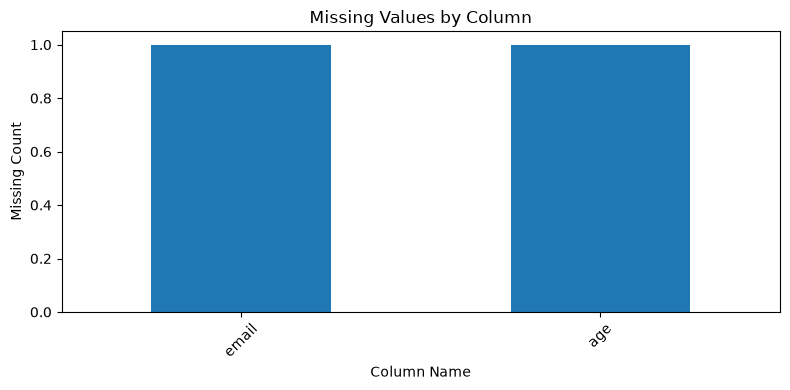

In [90]:
missing_counts = df_clean.isnull().sum()

missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(8, 4))
missing_counts.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Column Name")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(output_folder / "missing_values_chart.png", dpi=150)
plt.show()

## 13.2 Email Validation Visualization

This chart shows the distribution of email validation results.
Emails are classified as Valid, Invalid, or Missing.

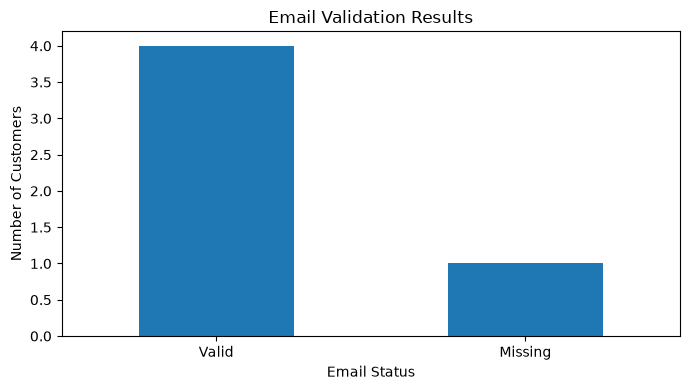

In [91]:
email_counts = df_clean["email_status"].value_counts()

plt.figure(figsize=(7, 4))
email_counts.plot(kind="bar")

plt.title("Email Validation Results")
plt.xlabel("Email Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(output_folder / "email_validation_chart.png", dpi=150)
plt.show()

## 13.3 Annual Income Distribution

This histogram visualizes the distribution of annual income
among customers in the cleaned dataset.

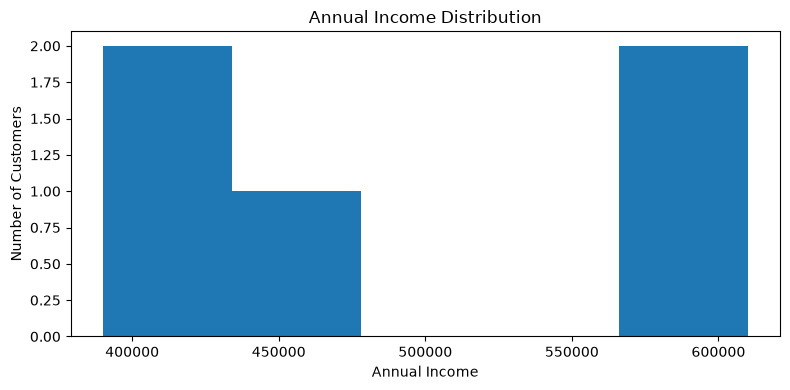

In [92]:
plt.figure(figsize=(8, 4))

df_clean["annual_income"].plot(kind="hist", bins=5)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(output_folder / "annual_income_histogram.png", dpi=150)
plt.show()

In [93]:
print("Visualization files:")

for file in output_folder.glob("*.png"):
    print(file.name)

Visualization files:
annual_income_histogram.png
missing_values_chart.png
email_validation_chart.png


## 14. Export Cleaned Dataset

The cleaned dataset and quality reports are exported to the output
folder for further analysis and project submission.

In [94]:
from pathlib import Path

output_folder = Path("../output")
output_folder.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_folder.resolve())

Output folder: /Users/shivji/Documents/ausbuildung-project/python-project/Data_Cleaning_Quality_Checker/output


In [97]:
# Cleaned dataset save in  CSV

csv_path = output_folder / "cleaned_customers.csv"

df_clean.to_csv(csv_path, index=False)

print("CSV file saved:", csv_path.resolve())

CSV file saved: /Users/shivji/Documents/ausbuildung-project/python-project/Data_Cleaning_Quality_Checker/output/cleaned_customers.csv


In [96]:
df_csv_check = pd.read_csv(csv_path)

print("Exported CSV shape:", df_csv_check.shape)
df_csv_check.head()

Exported CSV shape: (5, 8)


,customer_id,name,email,age,city,annual_income,signup_date,email_status
0,1001,Rahul Sharma,rahul@example.com,24.0,Delhi,420000,2024-01-12,Valid
1,1002,Priya Verma,priya@example.com,NaN,Mumbai,580000,2024-02-18,Valid
2,1003,Amit Kumar,amit@example.com,29.0,Delhi,610000,2024-03-07,Valid
3,1004,Neha Singh,neha@example.com,150.0,Mumbai,450000,2024-04-29,Valid
4,1005,Ravi Kumar,NaN,27.0,Delhi,390000,2024-05-10,Missing


In [98]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Total Missing Values",
        "Duplicate Records Remaining",
        "Missing Email Values",
        "Missing Age Values",
        "Invalid Age Values",
        "Invalid Email Values"
    ],
    "Value": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum()),
        int((df_clean["email_status"] == "Missing").sum()),
        int(df_clean["age"].isnull().sum()),
        int(
            (
                df_clean["age"].notna()
                & ~df_clean["age"].between(0, 120)
            ).sum()
        ),
        int((df_clean["email_status"] == "Invalid").sum())
    ]
})

quality_summary.to_csv(
    output_folder / "data_quality_report.csv",
    index=False
)

display(quality_summary)

,Metric,Value
0,Total Records,5
1,Total Columns,8
2,Total Missing Values,2
3,Duplicate Records Remaining,0
4,Missing Email Values,1
5,Missing Age Values,1
6,Invalid Age Values,1
7,Invalid Email Values,0


In [ ]:
# output files list

print("Files generated in output folder:\n")

for file in sorted(output_folder.iterdir()):
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size:,} bytes")

Files generated in output folder:

annual_income_histogram.png — 28,041 bytes
cleaned_customers.csv — 401 bytes
data_quality_report.csv — 186 bytes
email_validation_chart.png — 24,901 bytes
missing_values_chart.png — 23,101 bytes


## 15. Automated Data Quality Checker

A reusable function is created to automatically evaluate the quality
of a cleaned customer dataset.

The function checks:
- Total records and columns
- Missing values
- Duplicate records
- Missing emails
- Missing and invalid ages
- Invalid email formats

In [100]:
def run_quality_check(data):
    """
    Automatically checks the quality of a customer dataset.
    Returns a summary DataFrame.
    """

    total_records = len(data)
    total_columns = len(data.columns)
    total_missing = int(data.isnull().sum().sum())
    duplicate_records = int(data.duplicated().sum())

    # Check missing emails
    missing_emails = int(data["email"].isnull().sum())

    # Check missing and invalid ages
    missing_ages = int(data["age"].isnull().sum())

    invalid_ages = int(
        (
            data["age"].notna()
            & ~data["age"].between(0, 120)
        ).sum()
    )

    # Check invalid email formats, if email_status exists
    if "email_status" in data.columns:
        invalid_emails = int(
            (data["email_status"] == "Invalid").sum()
        )
    else:
        invalid_emails = None

    # Create a report
    report = pd.DataFrame({
        "Metric": [
            "Total Records",
            "Total Columns",
            "Total Missing Values",
            "Duplicate Records",
            "Missing Email Values",
            "Missing Age Values",
            "Invalid Age Values",
            "Invalid Email Values"
        ],
        "Value": [
            total_records,
            total_columns,
            total_missing,
            duplicate_records,
            missing_emails,
            missing_ages,
            invalid_ages,
            invalid_emails
        ]
    })

    return report

In [101]:
automated_report = run_quality_check(df_clean)

display(automated_report)

,Metric,Value
0,Total Records,5
1,Total Columns,8
2,Total Missing Values,2
3,Duplicate Records,0
4,Missing Email Values,1
5,Missing Age Values,1
6,Invalid Age Values,1
7,Invalid Email Values,0


In [ ]:
# automated report save in CSV

automated_report_path = output_folder / "automated_quality_report.csv"

automated_report.to_csv(automated_report_path, index=False)

print("Automated report saved successfully!")
print(automated_report_path.resolve())

Automated report saved successfully!
/Users/shivji/Documents/ausbuildung-project/python-project/Data_Cleaning_Quality_Checker/output/automated_quality_report.csv


## 17. Final Project Verification

This section verifies the cleaned dataset and confirms that the
main data quality requirements have been satisfied.

In [103]:
print("Final Dataset Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())

print(
    "Invalid Ages:",
    (
        df_clean["age"].notna()
        & ~df_clean["age"].between(0, 120)
    ).sum()
)

print("Missing Emails:", df_clean["email"].isnull().sum())
print("Missing Ages:", df_clean["age"].isnull().sum())
print("Invalid Emails:", (df_clean["email_status"] == "Invalid").sum())

Final Dataset Shape: (5, 8)
Total Missing Values: 2
Duplicate Rows: 0
Invalid Ages: 1
Missing Emails: 1
Missing Ages: 1
Invalid Emails: 0


In [104]:
# output files automated test

required_files = [
    "cleaned_customers.csv",
    "cleaned_customers.xlsx",
    "data_quality_report.csv",
    "automated_quality_report.csv",
    "missing_values_chart.png",
    "email_validation_chart.png",
    "annual_income_histogram.png"
]

for filename in required_files:
    file_path = output_folder / filename

    if file_path.exists():
        print(f"PASS: {filename}")
    else:
        print(f"MISSING: {filename}")

PASS: cleaned_customers.csv
MISSING: cleaned_customers.xlsx
PASS: data_quality_report.csv
PASS: automated_quality_report.csv
PASS: missing_values_chart.png
PASS: email_validation_chart.png
PASS: annual_income_histogram.png


In [105]:
exported_df = pd.read_csv(output_folder / "cleaned_customers.csv")

assert exported_df.shape == (5, 8), "Unexpected dataset dimensions!"
assert exported_df.duplicated().sum() == 0, "Duplicate rows detected!"

print("PASS: Exported CSV verification completed.")

PASS: Exported CSV verification completed.
